[np.float64(0.013672393086530937), np.float64(0.013757323474775556), np.float64(0.013843466199887229), np.float64(0.01393084683745164), np.float64(0.014019491684842586), np.float64(0.014109427786709216), np.float64(0.014200682961544281), np.float64(0.01429328582938677), np.float64(0.014387265840715433), np.float64(0.014482653306593169), np.float64(0.014579479430125141), np.float64(0.01467777633929769), np.float64(0.014777577121268598), np.float64(0.014878915858183623), np.float64(0.014981827664598503), np.float64(0.015086348726590388), np.float64(0.015192516342647653), np.float64(0.015300368966432354), np.float64(0.015409946251515445), np.float64(0.015521289098190632), np.float64(0.015634439702479908), np.float64(0.01574944160744967), np.float64(0.015866339756965248), np.float64(0.01598518055201809), np.float64(0.016106011909769676), np.float64(0.016228883325464374), np.float64(0.016353845937374056), np.float64(0.01648095259494689), np.float64(0.016610257930344947), np.float64(0.016741

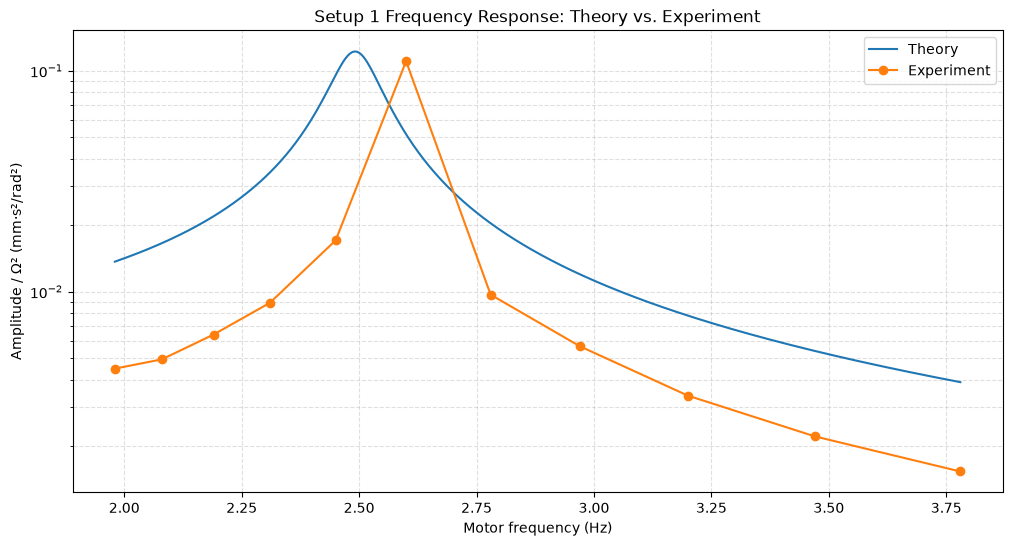

In [1]:
from numpy.fft import fft
import numpy as np
from matplotlib import pyplot as plt, ticker
import pandas as pd

motor_num_to_forcing_freq_hz = {
    12: 1.98,
    13: 2.08,
    14: 2.19,
    15: 2.31,
    16: 2.45,
    17: 2.60,
    18: 2.78,
    19: 2.97,
    20: 3.20,
    21: 3.47,
    22: 3.78,
}

forcing_freqs_hz = list(motor_num_to_forcing_freq_hz.values())
fft_amplitudes_at_forcing_freqs = []

sr = 240
n_fft=2**18
for i in range(12, 23):
        
        forcing_freq_hz = motor_num_to_forcing_freq_hz[i]
        
        df = pd.read_csv(f"../data/{i}.txt", sep="\t", skiprows=1)


        df = df.dropna(axis=1, how="all")


        t = df["t"]
        y = df["y"]
        mean = np.mean(y)

        # X = fft([v - mean for v in y])
        # N = len(X)
        # n = np.arange(N)
        # T = N/sr
        # freq = n/T
        
        # y = df[w + "y"]
        N = len(y) # use original non padded length
        norm_y = (np.array(y) - np.mean(y))*1000
        # data[w]["norm_y"] = norm_y
        window = np.hanning(N)
        X = fft(norm_y * window, n=n_fft)
        X *= 2 / np.sum(window)   # required bc more samples would make it misleadingly higher. 2 bc of neg freqs# replaces 2 / N when windowed
        n = np.arange(n_fft)
        T = n_fft/sr
        freq = n/T
        # data[w]["freqs"] = freq
        # data[w]["amplitudes"] = np.abs(X)
        
        # N = len(y) # use original non padded length
        # norm_y = (np.array(y) - np.mean(y))*1000
        # window = np.hanning(N)
        # X = fft(norm_y * window, n=n_fft)
        # X *= 2 / np.sum(window)   # required bc more samples would make it misleadingly higher. 2 bc of neg freqs# replaces 2 / N when windowed
        # n = np.arange(n_fft)
        # T = n_fft/sr
        # freq = n/T
        
        idx_of_closest_freq = np.argmin(np.abs(freq - forcing_freq_hz))
        
        fft_amplitude_at_closest_freq = abs(X)[idx_of_closest_freq]
        
        fft_amplitudes_at_forcing_freqs.append(fft_amplitude_at_closest_freq)


# Normalize
omega = 2 * np.pi * np.array(forcing_freqs_hz)
normalized_amp = np.array(fft_amplitudes_at_forcing_freqs) / (omega**2)

plt.figure(figsize = (12, 6))
# fig, ax = plt.subplots()
# ax.set_xticks(forcing_freqs_hz)
# ax.xaxis.set_major_formatter(ticker.FormatStrFormatter("%d"))
# ax.xaxis.set_minor_formatter(ticker.NullFormatter())

# η = Ω/15.661, then |MF|, then X̂ = 1.2422·|MF| mm, and divide by Ω² so it matches your plot.


# |MF| = 1/(2D)
# X_peak = 1.2422 / (2D) mm
# measured 30.0 mm at 2.60 Hz so
D = 1.2422 / (2 * 30.0)
theory_freqs = np.linspace(min(forcing_freqs_hz), max(forcing_freqs_hz), 500)
theory_amplitudes = []
for f in theory_freqs:
        omega = 2 * np.pi * f
        n = omega / 15.661
        abs_MF = n**2 / np.sqrt((1-n**2)**2 + (2 * D * n)**2)
        X = 1.2422 * abs_MF
        theory_amplitudes.append((X / omega **2)) # / omega^2 so it 
print(theory_amplitudes)
plt.plot(theory_freqs, theory_amplitudes, '-', label="Theory")
plt.plot(forcing_freqs_hz, normalized_amp, '-o', label="Experiment")
plt.legend()
plt.xlabel('Motor frequency (Hz)')
plt.ylabel('Amplitude / Ω² (mm·s²/rad²)')
# plt.xlim(min(forcing_freqs_hz), max(forcing_freqs_hz))
# rescale = 0.6
# plt.ylim(1*rescale, max(normalized_amp)*(1+(1-rescale)))
plt.yscale('log')
plt.grid(True, which='both', linestyle='--', alpha=0.4)
plt.title('Setup 1 Frequency Response: Theory vs. Experiment')
plt.savefig("../plots/frf_setup_1.png", dpi=300, bbox_inches='tight')

# plt.subplot(122)
# plt.plot(t, (y - np.mean(y))*1000, 'r')
# plt.xlabel('Time (s)')
# plt.ylabel('Amplitude (mm)')
# plt.ylim((min(y) - np.mean(y))*1000, (max(y)- np.mean(y))*1000)
# plt.xlim(0, max(t))
# plt.tight_layout()
# plt.show()